In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns

df = pd.read_csv("paddydataset.csv")
df

,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,...,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,...,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,...,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,...,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,...,SSE,W,SW,NW,72.7,91,83,81,600,34044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2784,1,Kallakurichi,CO_43,alluvial,25,12.5,wet,20,1,40,...,W,WNW,SE,S,88.5,95,81,84,90,5836
2785,1,Sankarapuram,ponmani,clay,25,12.5,wet,20,1,40,...,SSE,W,SW,NW,72.7,91,83,81,100,5723
2786,1,Chinnasalem,delux ponni,clay,25,12.5,wet,20,1,40,...,E,ENE,NE,NNW,78.6,80,92,88,80,5723
2787,1,Cuddalore,CO_43,alluvial,25,12.5,wet,20,1,40,...,SW,W,NNW,WSW,72.0,78,88,85,90,5916


In [55]:

df.columns = df.columns.str.strip()

display(df.head())

,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,...,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,...,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,...,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,...,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,...,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   str    
 2   Variety                             2789 non-null   str    
 3   Soil Types                          2789 non-null   str    
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   str    
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                         2789 non-null   fl

In [57]:
print(df.isnull().sum().sort_values(ascending=False))

Hectares                              0
Agriblock                             0
Variety                               0
Soil Types                            0
Seedrate(in Kg)                       0
LP_Mainfield(in Tonnes)               0
Nursery                               0
Nursery area (Cents)                  0
LP_nurseryarea(in Tonnes)             0
DAP_20days                            0
Weed28D_thiobencarb                   0
Urea_40Days                           0
Potassh_50Days                        0
Micronutrients_70Days                 0
Pest_60Day(in ml)                     0
30DRain( in mm)                       0
30DAI(in mm)                          0
30_50DRain( in mm)                    0
30_50DAI(in mm)                       0
51_70DRain(in mm)                     0
51_70AI(in mm)                        0
71_105DRain(in mm)                    0
71_105DAI(in mm)                      0
Min temp_D1_D30                       0
Max temp_D1_D30                       0


In [58]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 451


In [59]:
print("Total rows:", len(df))
print("Duplicate occurrences:", df.duplicated().sum())
print("Unique rows:", len(df.drop_duplicates()))

Total rows: 2789
Duplicate occurrences: 451
Unique rows: 2338


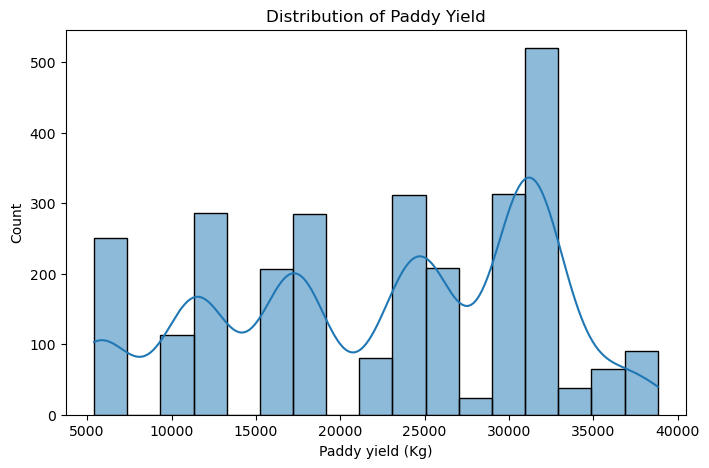

In [60]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Paddy yield(in Kg)"], kde=True)
plt.title("Distribution of Paddy Yield")
plt.xlabel("Paddy yield (Kg)")
plt.show()

In [61]:
X = df.drop("Paddy yield(in Kg)", axis=1)

y = df["Paddy yield(in Kg)"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2789, 44)
Target shape: (2789,)


In [62]:
cat_cols = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

num_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numerical columns:", len(num_cols))

Categorical columns: ['Agriblock', 'Variety', 'Soil Types', 'Nursery', 'Wind Direction_D1_D30', 'Wind Direction_D31_D60', 'Wind Direction_D61_D90', 'Wind Direction_D91_D120']
Numerical columns: 36


In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            cat_cols
        ),
        (
            "numerical",
            SimpleImputer(strategy="median"),
            num_cols
        )
    ]
)

In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2231
Testing samples: 558


In [65]:
from sklearn.ensemble import RandomForestRegressor

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [66]:
from sklearn.ensemble import RandomForestRegressor

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [67]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Generate predictions from your model first 
# (Make sure 'model' and 'X_test' were created in earlier cells)
y_pred = model.predict(X_test)

# 2. Calculate the metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"R²: {r2}")

MAE: 632.2079486039477
RMSE: 887.2069366828164
R²: 0.990295442349034


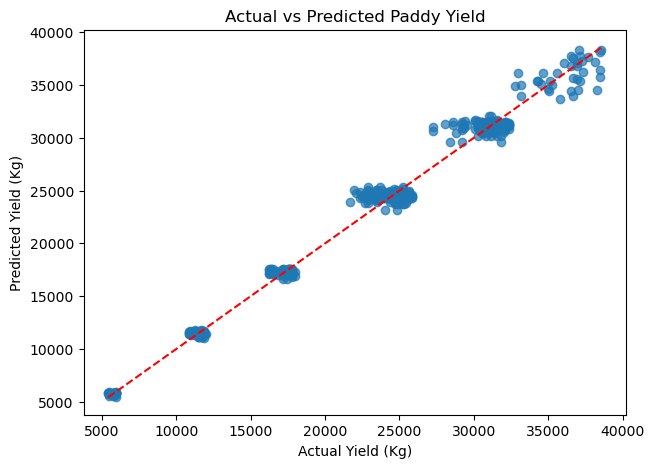

In [68]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.xlabel("Actual Yield (Kg)")
plt.ylabel("Predicted Yield (Kg)")
plt.title("Actual vs Predicted Paddy Yield")

# Reference line
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.show()

In [69]:
# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Random Forest feature importances
importances = model.named_steps[
    "regressor"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
36,numerical__Seedrate(in Kg),0.105044
43,numerical__Potassh_50Days,0.101535
44,numerical__Micronutrients_70Days,0.098910
38,numerical__Nursery area (Cents),0.096080
37,numerical__LP_Mainfield(in Tonnes),0.093019
45,numerical__Pest_60Day(in ml),0.086292
42,numerical__Urea_40Days,0.085759
41,numerical__Weed28D_thiobencarb,0.075561
40,numerical__DAP_20days,0.065548
39,numerical__LP_nurseryarea(in Tonnes),0.065266


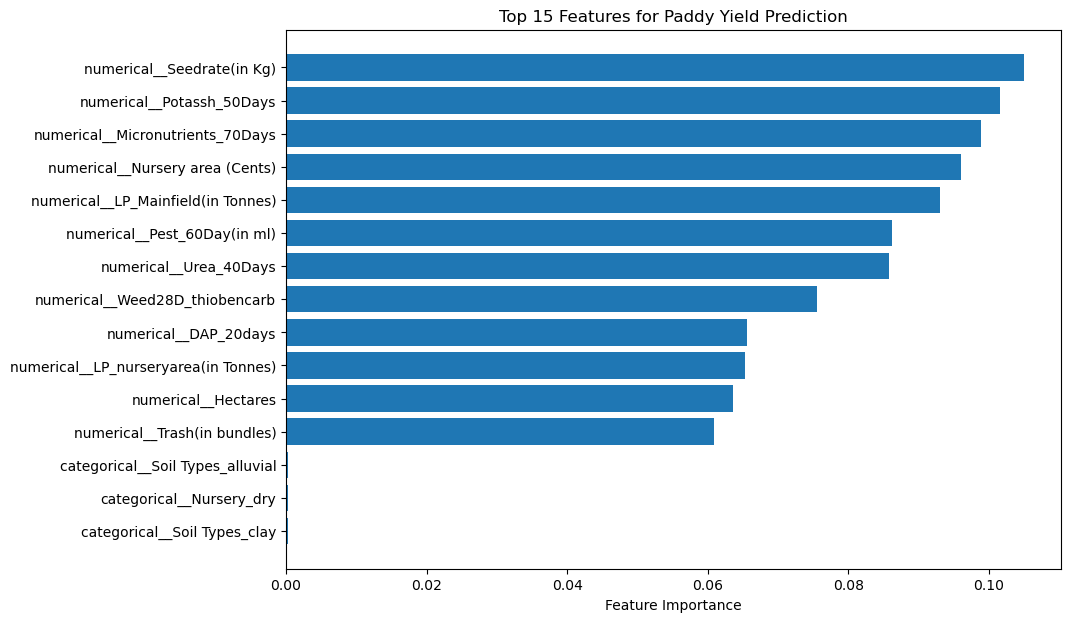

In [70]:
top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features for Paddy Yield Prediction")
plt.show()

In [71]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [None, 10, 20],
    "regressor__min_samples_split": [2, 5],
    "regressor__min_samples_leaf": [1, 2]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV RMSE:", round(-grid.best_score_, 2), "Kg")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'regressor__max_depth': 10, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 300}
Best CV RMSE: 837.57 Kg


In [72]:
best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print(
    "Test MAE:",
    round(mean_absolute_error(y_test, y_pred_tuned), 2)
)

print(
    "Test RMSE:",
    round(np.sqrt(mean_squared_error(y_test, y_pred_tuned)), 2)
)

print(
    "Test R2:",
    round(r2_score(y_test, y_pred_tuned), 4)
)

Test MAE: 619.98
Test RMSE: 870.85
Test R2: 0.9906


In [73]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Baseline Random Forest": [
        mean_absolute_error(y_test, y_pred),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        r2_score(y_test, y_pred)
    ],
    "Tuned Random Forest": [
        mean_absolute_error(y_test, y_pred_tuned),
        np.sqrt(mean_squared_error(y_test, y_pred_tuned)),
        r2_score(y_test, y_pred_tuned)
    ]
})

display(comparison.round(4))

,Metric,Baseline Random Forest,Tuned Random Forest
0,MAE,632.2079,619.9815
1,RMSE,887.2069,870.8547
2,R2 Score,0.9903,0.9906
